<a href="https://colab.research.google.com/github/tikakukeko/Studi_Kasus_Dan_Implementasi_Kode_Atikah_Putri_Utami_G1A024027/blob/main/Studi_Kasus_Career_and_Competition_in_Industrial_Era_with_GIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## Studi Kasus Lengkap: Konteks, Analisis, dan Rekomendasi

### A. Latar belakang
Organisasi yang memiliki banyak aset—misalnya lampu jalan, rambu, fasilitas umum, atau perangkat jaringan—perlu mengetahui lokasi, kondisi, dan tingkat urgensi pemeliharaan setiap aset. Pemeriksaan manual tanpa prioritas dapat menghabiskan waktu dan membuat aset kritis terlambat ditangani. GIS (Geographic Information System) membantu menggabungkan informasi atribut dengan lokasi geografis agar keputusan pemeliharaan lebih terarah.

### B. Rumusan masalah
1. Bagaimana kondisi dan sebaran aset yang tercatat?
2. Aset mana yang membutuhkan inspeksi lebih dahulu?
3. Bagaimana jarak aset dari kantor dapat membantu perencanaan kunjungan?
4. Bagaimana hasil analisis dapat disimpan untuk digunakan pada sistem GIS lain?

### C. Tujuan dan manfaat
- Menginventarisasi atribut dan lokasi aset.
- Membuat skor prioritas awal berdasarkan aturan yang transparan.
- Menyusun daftar kandidat inspeksi untuk membantu tim operasional.
- Menyiapkan data yang dapat diekspor ke CSV dan dikembangkan di QGIS atau PostGIS.

### D. Definisi variabel
- `asset_id`: identitas unik aset.
- `asset_name`: nama aset.
- `category`: jenis aset.
- `condition`: kondisi aset yang tercatat.
- `age_years`: usia aset dalam tahun, jika tersedia.
- `criticality`: tingkat kepentingan aset.
- `failure_count` atau riwayat gangguan: indikasi masalah berulang.
- `latitude` dan `longitude`: koordinat geografis.
- `distance_from_office_km`: perkiraan jarak dari kantor.
- `priority_score` dan `priority_level`: skor dan kategori prioritas yang dihitung.

Nama kolom persisnya mengikuti kolom yang tersedia di bagian pembuatan dataset notebook.

### E. Alur kerja analisis
1. **Memahami kebutuhan:** tentukan aset yang harus dipantau dan arti prioritas bagi organisasi.
2. **Memeriksa data:** pastikan ID tidak duplikat, koordinat masuk akal, kondisi konsisten, dan nilai kosong teridentifikasi.
3. **Mengolah data spasial:** gunakan latitude dan longitude untuk memetakan aset dan menghitung jarak perkiraan.
4. **Menentukan prioritas:** gabungkan kondisi, usia, tingkat kepentingan, dan riwayat gangguan menggunakan aturan berbobot.
5. **Menyusun daftar inspeksi:** urutkan skor tertinggi terlebih dahulu; jarak dapat menjadi pertimbangan operasional setelah faktor keselamatan.
6. **Mengekspor hasil:** simpan tabel agar dapat diperiksa ulang dan digunakan di aplikasi GIS.

### F. Cara membaca hasil
Skor prioritas adalah alat bantu penyaringan, bukan keputusan pemeliharaan otomatis. Skor yang lebih tinggi berarti aset lebih layak ditinjau lebih dahulu menurut aturan yang ditetapkan. Periksa juga nilai sumbernya: aset yang kritis atau berbahaya tidak boleh diturunkan prioritasnya hanya karena lokasinya jauh.

Jika peta atau daftar inspeksi menunjukkan aset mengelompok pada area tertentu, hal tersebut dapat membantu perencanaan rute. Namun, jarak garis lurus bukan selalu jarak perjalanan jalan raya dan tidak memperhitungkan kemacetan, akses, atau kondisi lapangan.

### G. Validasi dan risiko
- Verifikasi koordinat terhadap peta atau survei lapangan.
- Pastikan bobot skor disetujui pengelola aset.
- Catat tanggal pembaruan kondisi dan sumber data.
- Hindari menyimpulkan bahwa aset aman hanya karena skor rendah.
- Uji hasil prioritas dengan catatan inspeksi dan keputusan ahli.
- Lindungi lokasi aset sensitif bila data dibagikan secara publik.

### H. Rekomendasi implementasi
Mulailah dengan dataset kecil dan aturan yang mudah dijelaskan. Setelah proses disetujui, hubungkan data dengan QGIS atau database spasial seperti PostGIS. Pengembangan berikutnya dapat mencakup peta interaktif, filter kategori, riwayat inspeksi, dan pembaruan status aset.

### I. Kesimpulan studi kasus
GIS membantu menggabungkan informasi lokasi dengan kondisi dan karakteristik aset untuk menghasilkan daftar prioritas inspeksi. Nilai utama proyek ini adalah dukungan pengambilan keputusan yang lebih terstruktur. Kualitas rekomendasi tetap bergantung pada kelengkapan data, validitas koordinat, dan kesesuaian aturan prioritas dengan prosedur organisasi.

**Batas interpretasi:** bila notebook menggunakan data sintetis, seluruh hasil hanya demonstrasi alur analisis dan tidak menggambarkan aset nyata.


## 1. Import library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import radians, sin, cos, sqrt, atan2

RANDOM_STATE = 42
print("Library berhasil diimpor.")

Library berhasil diimpor.


## 2. Membuat dataset aset simulasi



In [2]:
rng = np.random.default_rng(RANDOM_STATE)
n_assets = 30

# Titik tengah latihan di sekitar Bengkulu; semua titik aset di bawah bersifat sintetis.
center_lat = -3.800
center_lon = 102.265

categories = ["Lampu jalan", "Rambu", "Drainase", "Bangunan", "Jaringan"]
conditions = ["Baik", "Sedang", "Buruk"]

df = pd.DataFrame({
    "asset_id": [f"AST-{i:03d}" for i in range(1, n_assets + 1)],
    "asset_name": [f"Aset {i:02d}" for i in range(1, n_assets + 1)],
    "category": rng.choice(categories, n_assets),
    "latitude": center_lat + rng.normal(0, 0.018, n_assets),
    "longitude": center_lon + rng.normal(0, 0.020, n_assets),
    "condition": rng.choice(conditions, n_assets, p=[0.40, 0.38, 0.22]),
    "age_years": rng.integers(1, 26, n_assets),
    "criticality": rng.integers(1, 6, n_assets),
    "incidents_last_year": rng.integers(0, 9, n_assets),
})

df["latitude"] = df["latitude"].round(6)
df["longitude"] = df["longitude"].round(6)

# Simpan data simulasi agar bisa dipakai kembali.
df.to_csv("data_aset_gis_simulasi.csv", index=False)
display(df.head(10))

,asset_id,asset_name,category,latitude,longitude,condition,age_years,criticality,incidents_last_year
0,AST-001,Aset 01,Lampu jalan,-3.815467,102.269374,Sedang,19,4,3
1,AST-002,Aset 02,Bangunan,-3.793362,102.282429,Sedang,7,1,4
2,AST-003,Aset 03,Bangunan,-3.817260,102.269472,Buruk,2,4,4
3,AST-004,Aset 04,Drainase,-3.784188,102.278578,Sedang,3,3,7
4,AST-005,Aset 05,Drainase,-3.800899,102.266352,Sedang,12,4,0
5,AST-006,Aset 06,Jaringan,-3.803328,102.270782,Buruk,23,1,0
6,AST-007,Aset 07,Lampu jalan,-3.812257,102.277626,Baik,4,1,2
7,AST-008,Aset 08,Bangunan,-3.777994,102.235857,Baik,12,3,4
8,AST-009,Aset 09,Rambu,-3.802782,102.258607,Baik,18,1,6
9,AST-010,Aset 10,Lampu jalan,-3.807710,102.255593,Sedang,6,2,4


## 3. Memeriksa kualitas data

In [3]:
print("Ukuran data:", df.shape)
print("\nNilai kosong per kolom:")
display(df.isna().sum().to_frame("missing_values"))

print("\nRingkasan numerik:")
display(df[["latitude", "longitude", "age_years", "criticality", "incidents_last_year"]].describe().round(3))

Ukuran data: (30, 9)

Nilai kosong per kolom:


,missing_values
asset_id,0
asset_name,0
category,0
latitude,0
longitude,0
condition,0
age_years,0
criticality,0
incidents_last_year,0



Ringkasan numerik:


,latitude,longitude,age_years,criticality,incidents_last_year
count,30.000,30.000,30.000,30.000,30.000
mean,-3.798,102.264,12.133,2.633,3.867
std,0.013,0.016,6.601,1.426,2.501
min,-3.817,102.231,1.000,1.000,0.000
25%,-3.809,102.256,6.250,1.000,2.000
50%,-3.799,102.267,12.500,3.000,4.000
75%,-3.790,102.277,17.750,4.000,5.750
max,-3.761,102.295,23.000,5.000,8.000


## 4. Menghitung skor prioritas pemeliharaan



In [4]:
condition_points = {"Baik": 0, "Sedang": 25, "Buruk": 50}

df["condition_points"] = df["condition"].map(condition_points)
df["priority_score"] = (
    df["condition_points"]
    + df["criticality"] * 8
    + df["age_years"] * 1.2
    + df["incidents_last_year"] * 4
).round(1)

df["priority_level"] = pd.cut(
    df["priority_score"],
    bins=[-np.inf, 45, 70, np.inf],
    labels=["Rendah", "Sedang", "Tinggi"]
)

priority_table = df.sort_values("priority_score", ascending=False)[
    ["asset_id", "asset_name", "category", "condition", "age_years",
     "criticality", "incidents_last_year", "priority_score", "priority_level"]
]
display(priority_table.head(10))

,asset_id,asset_name,category,condition,age_years,criticality,incidents_last_year,priority_score,priority_level
22,AST-023,Aset 23,Lampu jalan,Buruk,17,3,7,122.4,Tinggi
29,AST-030,Aset 30,Drainase,Sedang,17,5,8,117.4,Tinggi
2,AST-003,Aset 03,Bangunan,Buruk,2,4,4,100.4,Tinggi
0,AST-001,Aset 01,Lampu jalan,Sedang,19,4,3,91.8,Tinggi
10,AST-011,Aset 11,Drainase,Sedang,19,4,3,91.8,Tinggi
23,AST-024,Aset 24,Jaringan,Buruk,11,2,3,91.2,Tinggi
12,AST-013,Aset 13,Bangunan,Sedang,21,4,1,86.2,Tinggi
5,AST-006,Aset 06,Jaringan,Buruk,23,1,0,85.6,Tinggi
26,AST-027,Aset 27,Drainase,Buruk,4,2,3,82.8,Tinggi
3,AST-004,Aset 04,Drainase,Sedang,3,3,7,80.6,Tinggi


## 5. Visualisasi sebaran aset berdasarkan koordinat


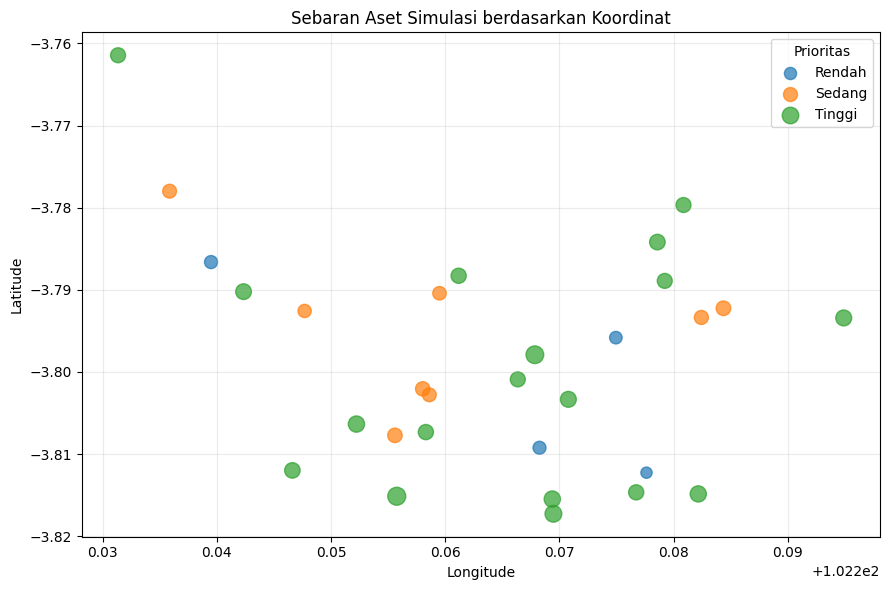

In [5]:
color_map = {"Rendah": "green", "Sedang": "orange", "Tinggi": "red"}

plt.figure(figsize=(9, 6))
for level, group in df.groupby("priority_level", observed=False):
    plt.scatter(
        group["longitude"], group["latitude"],
        label=str(level),
        s=45 + group["priority_score"],
        alpha=0.7
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Sebaran Aset Simulasi berdasarkan Koordinat")
plt.legend(title="Prioritas")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Menghitung jarak dari kantor pemeliharaan



In [6]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Menghitung perkiraan jarak permukaan bumi dalam kilometer."""
    earth_radius_km = 6371.0
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))
    return earth_radius_km * c

# Titik kantor pemeliharaan simulasi
office_lat = -3.805
office_lon = 102.270

df["distance_from_office_km"] = df.apply(
    lambda row: haversine_km(
        office_lat, office_lon, row["latitude"], row["longitude"]
    ),
    axis=1
).round(2)

display(
    df.sort_values(["priority_score", "distance_from_office_km"],
                   ascending=[False, True])[
        ["asset_id", "asset_name", "priority_score",
         "priority_level", "distance_from_office_km"]
    ].head(10)
)

,asset_id,asset_name,priority_score,priority_level,distance_from_office_km
22,AST-023,Aset 23,122.4,Tinggi,1.94
29,AST-030,Aset 30,117.4,Tinggi,0.82
2,AST-003,Aset 03,100.4,Tinggi,1.36
0,AST-001,Aset 01,91.8,Tinggi,1.17
10,AST-011,Aset 11,91.8,Tinggi,1.98
23,AST-024,Aset 24,91.2,Tinggi,1.74
12,AST-013,Aset 13,86.2,Tinggi,3.05
5,AST-006,Aset 06,85.6,Tinggi,0.21
26,AST-027,Aset 27,82.8,Tinggi,3.48
3,AST-004,Aset 04,80.6,Tinggi,2.50


## 7. Menentukan kandidat inspeksi


In [7]:
inspection_candidates = df.sort_values(
    ["priority_score", "distance_from_office_km"],
    ascending=[False, True]
).head(5)

display(inspection_candidates[
    ["asset_id", "asset_name", "category", "condition",
     "priority_score", "priority_level", "distance_from_office_km"]
])

,asset_id,asset_name,category,condition,priority_score,priority_level,distance_from_office_km
22,AST-023,Aset 23,Lampu jalan,Buruk,122.4,Tinggi,1.94
29,AST-030,Aset 30,Drainase,Sedang,117.4,Tinggi,0.82
2,AST-003,Aset 03,Bangunan,Buruk,100.4,Tinggi,1.36
0,AST-001,Aset 01,Lampu jalan,Sedang,91.8,Tinggi,1.17
10,AST-011,Aset 11,Drainase,Sedang,91.8,Tinggi,1.98


## 8. Ringkasan analisis

In [8]:
print("Jumlah aset:", len(df))
print("\nJumlah aset per tingkat prioritas:")
display(df["priority_level"].value_counts().rename_axis("priority_level").to_frame("jumlah_aset"))

print("\nRata-rata skor prioritas:", round(df["priority_score"].mean(), 2))
print("Aset dengan skor tertinggi:")
display(df.nlargest(1, "priority_score")[
    ["asset_id", "asset_name", "condition", "priority_score", "priority_level"]
])

Jumlah aset: 30

Jumlah aset per tingkat prioritas:


,jumlah_aset
priority_level,
Tinggi,18
Sedang,8
Rendah,4



Rata-rata skor prioritas: 71.09
Aset dengan skor tertinggi:


,asset_id,asset_name,condition,priority_score,priority_level
22,AST-023,Aset 23,Buruk,122.4,Tinggi


## 9. Mengekspor hasil analisis

In [9]:
output_file = "hasil_analisis_prioritas_aset.csv"
df.sort_values("priority_score", ascending=False).to_csv(output_file, index=False)
print(f"Hasil analisis disimpan ke: {output_file}")

Hasil analisis disimpan ke: hasil_analisis_prioritas_aset.csv
